# Task 1A + 1B: Understanding Beijing's PM2.5 data

## Problem definition

PM2.5 means airborne particles smaller than 2.5 micrometres, about 30 times thinner than a human hair. They're small enough to get deep into the lungs and bloodstream, and long exposure is linked to heart and lung disease. Beijing has had some of the worst PM2.5 levels of any major city, with winter smog episodes reaching several hundred µg/m³.

**Our problem:** forecast **next hour's PM2.5 level** from the last 24 hours of pollution and the latest weather. A one-hour warning gives people, schools and hospitals time to act (stay indoors, close windows, move outdoor activities) before the bad air arrives.

**Why this dataset**
- **A long, regular record:** 5 years of hourly readings from one fixed monitor at the US Embassy, which is a trusted source
- **The target and its drivers in one file:** PM2.5 sits alongside the weather that drives it (wind, humidity, pressure, rain, snow)
- **Real-world mess:** it has genuine missing values, which lets us show proper preprocessing
- **Open and citable:** [Kaggle](https://www.kaggle.com/datasets/djhavera/beijing-pm25-data-data-set), originally from the [UCI ML Repository](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data) (CC BY 4.0); Liang et al. (2015), *Proceedings of the Royal Society A*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from load_data import load_raw

FIG_DIR = ROOT / "outputs" / "figures"
plt.rcParams["figure.figsize"] = (11, 4)
sns.set_theme(style="whitegrid")

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=150)
    plt.show()

raw = load_raw()
raw.head()

,datetime,pm25,dew_point,temperature,pressure,wind_dir,wind_speed,hours_snow,hours_rain
0,2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


## 1. Time range and frequency

In [2]:
gaps = raw.datetime.diff().value_counts()

print(f"From {raw.datetime.min()} to {raw.datetime.max()}")
print(f"{len(raw):,} rows over {raw.datetime.dt.year.nunique()} years")
print("Time step between rows:")
print(gaps)

From 2010-01-01 00:00:00 to 2014-12-31 23:00:00
43,824 rows over 5 years
Time step between rows:
datetime
0 days 01:00:00    43823
Name: count, dtype: int64


- **Range:** 1 Jan 2010 to 31 Dec 2014, which is 5 full years.
- **Frequency:** hourly. Every gap between rows is exactly 1 hour, so **no timestamps are missing**, only some values. That's important: lag features like "1 hour ago" or "24 hours ago" can be made with a simple shift and will always mean the right time.

## 2. Summary statistics

In [3]:
num_cols = ["pm25", "dew_point", "temperature", "pressure", "wind_speed", "hours_snow", "hours_rain"]
stats = raw[num_cols].describe().T
stats["skew"] = raw[num_cols].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
pm25,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0,1.80
dew_point,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0,-0.15
temperature,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0,-0.16
pressure,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0,0.10
wind_speed,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6,4.30
hours_snow,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0,19.48
hours_rain,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0,11.66


In [4]:
print("Wind direction counts:")
print(raw.wind_dir.value_counts())
print(f"\nHours with no snow: {(raw.hours_snow == 0).mean():.1%}, no rain: {(raw.hours_rain == 0).mean():.1%}")
print(f"Hours with PM2.5 above 75 µg/m³ (China's 24-hour limit): {(raw.pm25 > 75).mean():.1%}")
print(f"Hours above 250 µg/m³ (hazardous): {(raw.pm25 > 250).mean():.1%}")

Wind direction counts:
wind_dir
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

Hours with no snow: 99.2%, no rain: 95.9%
Hours with PM2.5 above 75 µg/m³ (China's 24-hour limit): 46.2%
Hours above 250 µg/m³ (hazardous): 7.0%


## 3. Distributions

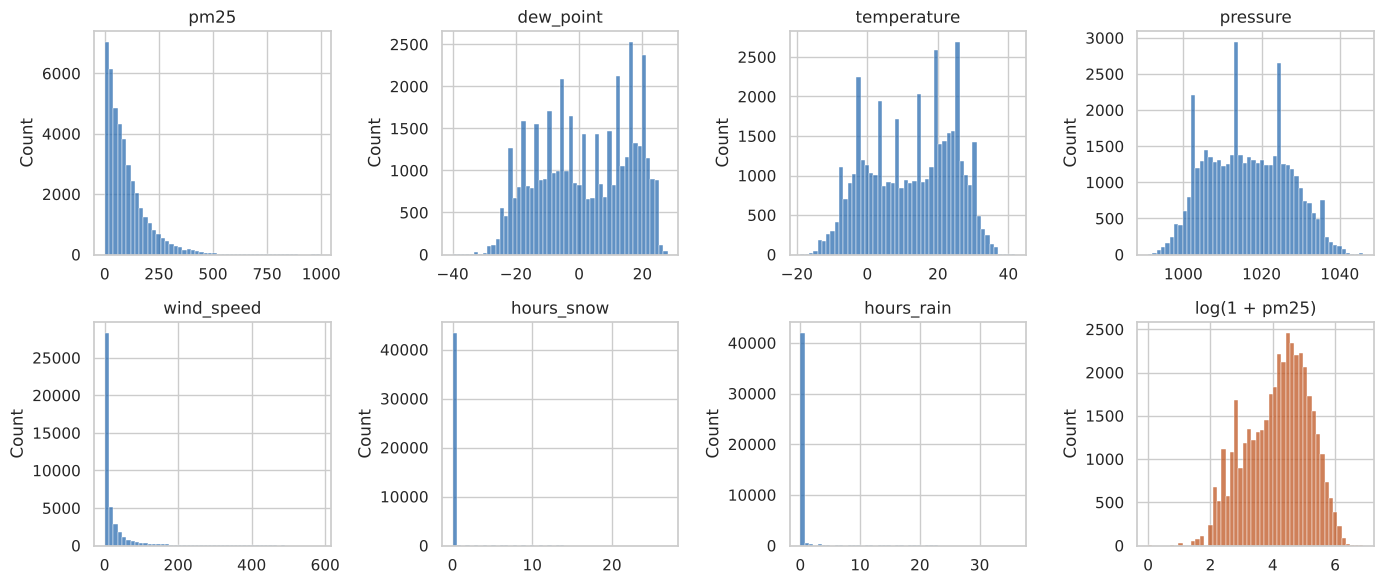

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(raw[col].dropna(), bins=50, ax=ax, color="#2b6cb0")
    ax.set_title(col)
    ax.set_xlabel("")
sns.histplot(np.log1p(raw.pm25.dropna()), bins=50, ax=axes.flat[-1], color="#c05621")
axes.flat[-1].set_title("log(1 + pm25)")
axes.flat[-1].set_xlabel("")
save("distributions")

**What the distributions show**

- **PM2.5 is strongly right-skewed (skew 1.8).** The median is 72 µg/m³ but the mean is 99, pulled up by smog spikes reaching 994. On a log scale it looks roughly bell-shaped. The extreme values are real smog events, not errors, so we **keep them**: they're exactly the hours a warning system exists for.
- **The air is often unhealthy.** 46% of hours are above 75 µg/m³, China's 24-hour limit, and 7% are above 250.
- **Temperature, dew point and pressure** have a broad two-peaked shape, from summer versus winter.
- **Wind speed is cumulative.** The column adds up speed for as long as the direction stays the same, which is why it has a long tail up to 585. It still works as "how long and how hard has the wind been blowing".
- **Snow and rain are almost always zero** (99.2% and 95.9% of hours), so on their own they'll carry little signal.

## 4. Missing values

Only `pm25` has missing values. Every weather column is complete.

In [6]:
pm = raw.set_index("datetime").pm25
missing = pm.isna()
print(raw.isna().sum())

# Group consecutive missing hours into gaps
run_id = (missing != missing.shift()).cumsum()
gap_lengths = missing.groupby(run_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]

print(f"\nMissing PM2.5 hours: {missing.sum():,} ({missing.mean():.1%})")
print(f"Separate gaps: {len(gap_lengths)}, longest: {gap_lengths.max()} hours")
print(pd.cut(gap_lengths, [0, 1, 3, 6, 24, 200]).value_counts().sort_index())

datetime          0
pm25           2067
dew_point         0
temperature       0
pressure          0
wind_dir          0
wind_speed        0
hours_snow        0
hours_rain        0
dtype: int64

Missing PM2.5 hours: 2,067 (4.7%)
Separate gaps: 214, longest: 155 hours
pm25
(0, 1]       112
(1, 3]        31
(3, 6]        15
(6, 24]       36
(24, 200]     20
Name: count, dtype: int64


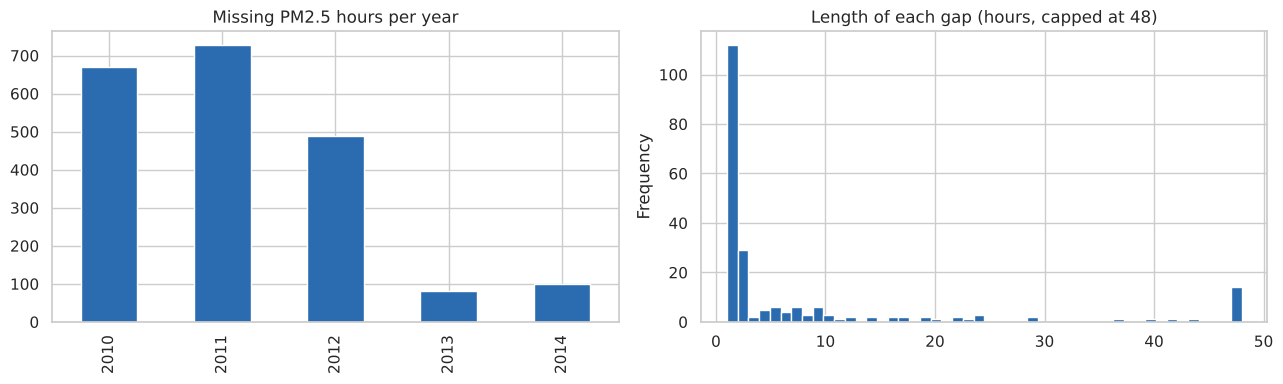

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
missing.groupby(pm.index.year).sum().plot.bar(ax=axes[0], color="#2b6cb0")
axes[0].set_title("Missing PM2.5 hours per year")
axes[0].set_xlabel("")
gap_lengths.clip(upper=48).plot.hist(bins=48, ax=axes[1], color="#2b6cb0")
axes[1].set_title("Length of each gap (hours, capped at 48)")
save("missing_values")

- **2,067 hours (4.7%) are missing,** spread across 214 separate gaps.
- **Most gaps are tiny:** 112 of them last a single hour. But a few are long, up to 155 hours (about 6.5 days), probably monitor outages.
- **Missing data falls sharply after 2012** (from about 700 hours a year to under 100), so the later years are cleaner.

### Choosing how to fill the gaps

We don't just pick a method, we **test** them. We take stretches with no missing data, blank out an artificial gap of 1 to 24 hours, fill it three ways, and measure how wrong each fill is:
- **Linear interpolation:** draw a straight line between the hour before and the hour after
- **Forward fill:** repeat the last known value
- **Mean fill:** use the average of the surrounding two days

In [8]:
rng = np.random.default_rng(0)
rows = []
for gap in [1, 3, 6, 12, 24]:
    errors = {"linear": [], "forward_fill": [], "mean_fill": []}
    for _ in range(400):
        i = rng.integers(48, len(pm) - 48)
        window = pm.iloc[i - 24 : i + gap + 24]
        if window.isna().any():
            continue  # only test on stretches we know the truth for
        truth = window.iloc[24 : 24 + gap]
        blank = window.copy()
        blank.iloc[24 : 24 + gap] = np.nan
        fills = {
            "linear": blank.interpolate(),
            "forward_fill": blank.ffill(),
            "mean_fill": blank.fillna(blank.mean()),
        }
        for name, filled in fills.items():
            errors[name].append((filled.iloc[24 : 24 + gap] - truth).abs().mean())
    rows.append({"gap_hours": gap, **{k: np.mean(v) for k, v in errors.items()}})

fill_test = pd.DataFrame(rows).set_index("gap_hours").round(1)
fill_test

,linear,forward_fill,mean_fill
gap_hours,,,
1,9.0,13.2,38.2
3,12.1,19.5,41.0
6,17.0,29.4,42.5
12,25.1,36.4,46.2
24,38.9,53.5,54.4


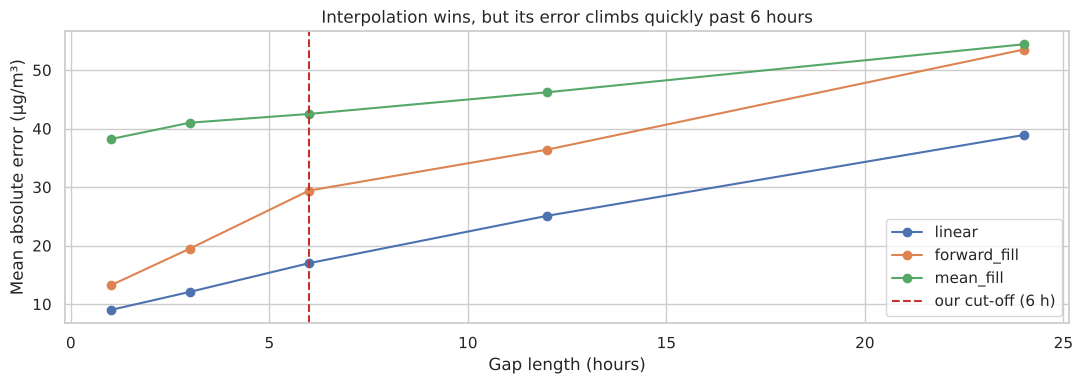

In [9]:
fill_test.plot(marker="o")
plt.axvline(6, color="#c53030", linestyle="--", label="our cut-off (6 h)")
plt.ylabel("Mean absolute error (µg/m³)")
plt.xlabel("Gap length (hours)")
plt.title("Interpolation wins, but its error climbs quickly past 6 hours")
plt.legend()
save("fill_method_test")

**Decision: linearly interpolate gaps of 6 hours or less, and leave longer gaps empty.**

- **Linear interpolation is the most accurate at every gap length.** It beats forward fill by roughly 30 to 40%, because PM2.5 rises and falls smoothly, so a line between the two ends follows it well.
- **We stop at 6 hours because the error keeps climbing.** At 1 hour it's about 9 µg/m³. By 12 to 24 hours it approaches what you'd get from just guessing the average (mean fill), which means we'd be inventing data rather than recovering it. Think of it like a gap in a video: you can smoothly fill a few dropped frames, but you can't make up a whole missing scene.
- **Long gaps are dropped, not filled.** The rows inside them can't produce complete features, so the modelling step removes them. That costs about 6.5% of rows, which is a fair price for not training on made-up values.

This logic lives in `src/preprocessing.py` as `clean()`, so the model and the prediction script fill gaps exactly the same way.

In [10]:
from preprocessing import clean, MAX_GAP_HOURS

df = clean(raw)
print(f"Cut-off: {MAX_GAP_HOURS} hours")
print(f"Missing before: {raw.pm25.isna().sum():,}  after filling short gaps: {df.pm25.isna().sum():,}")

Cut-off: 6 hours
Missing before: 2,067  after filling short gaps: 1,817


## 5. Analytical questions

Six questions, each answered with a plot and an interpretation. **Q1, Q3, Q4 and Q6 use moving averages or lagged features,** which meets the requirement of at least two.

### Q1. Is Beijing's PM2.5 getting better or worse over 2010 to 2014?
*(uses a 30-day moving average)*

Hourly data is too noisy to see a trend, so we smooth it with a 30-day moving average. Think of it like judging someone's fitness by their monthly average step count rather than one day's.

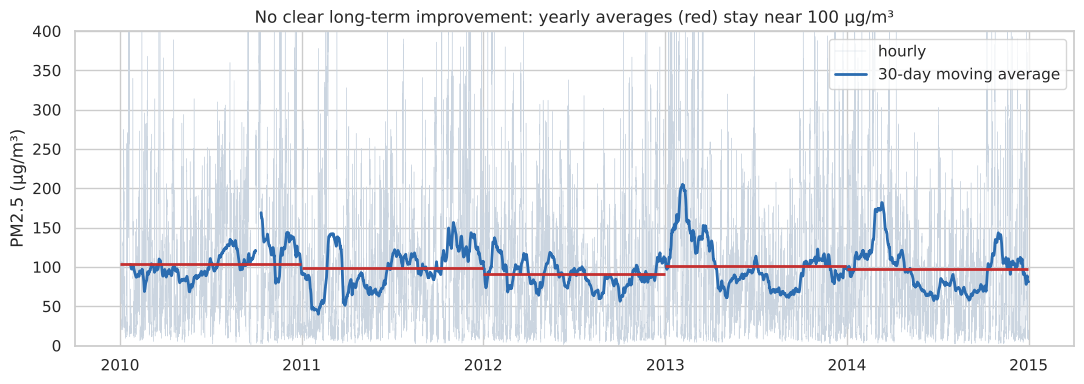

datetime
2010    104.1
2011     99.1
2012     90.5
2013    101.7
2014     97.6
Name: pm25, dtype: float64

In [11]:
ma30 = df.pm25.rolling(24 * 30, min_periods=24 * 20).mean()
yearly = df.pm25.groupby(df.index.year).mean()

plt.plot(df.index, df.pm25, color="#cbd5e0", linewidth=0.3, label="hourly")
plt.plot(ma30.index, ma30, color="#2b6cb0", linewidth=2, label="30-day moving average")
for year, value in yearly.items():
    plt.hlines(value, pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year}-12-31"),
               color="#c53030", linewidth=2)
plt.ylim(0, 400)
plt.ylabel("PM2.5 (µg/m³)")
plt.title("No clear long-term improvement: yearly averages (red) stay near 100 µg/m³")
plt.legend(loc="upper right")
save("q1_trend")
yearly.round(1)

**Finding:** there's **no clear long-term trend.** Yearly averages move between 90 and 104 µg/m³, dipping in 2012 and bouncing back in 2013, the year of Beijing's notorious January smog crisis. Every year sits far above the WHO's 24-hour guideline of 15 µg/m³.

The 30-day moving average shows that the **real pattern is seasonal, not long-term**: a peak every winter and a lower level every summer, repeating each year. So the model needs to know what time of year it is. That's Q2.

### Q2. When in the year and the day is pollution worst?

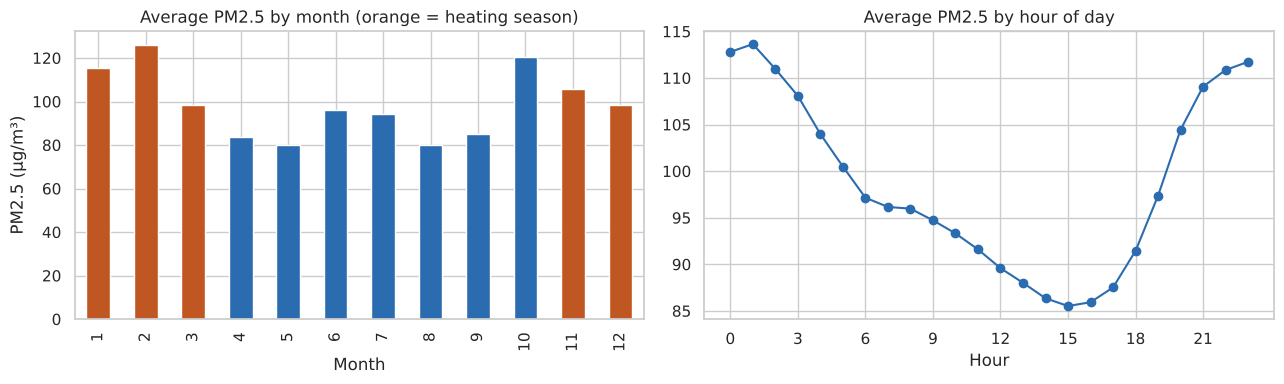

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_month = df.pm25.groupby(df.index.month).mean()
by_month.plot.bar(ax=axes[0], color=["#c05621" if m in (11, 12, 1, 2, 3) else "#2b6cb0" for m in by_month.index])
axes[0].set_title("Average PM2.5 by month (orange = heating season)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("PM2.5 (µg/m³)")

by_hour = df.pm25.groupby(df.index.hour).mean()
by_hour.plot(ax=axes[1], marker="o", color="#2b6cb0")
axes[1].set_title("Average PM2.5 by hour of day")
axes[1].set_xlabel("Hour")
axes[1].set_xticks(range(0, 24, 3))
save("q2_seasonality")

**Finding:** pollution has a strong **yearly** cycle and a clear **daily** cycle.

- **By month:** February (126 µg/m³) and January are the worst, followed by October and November. August and May are the cleanest (about 80). Winter is the worst season because Beijing burns coal for heating from mid-November to mid-March, and cold, still air traps the smoke.
- **By hour:** pollution peaks around **midnight to 1 am (about 114)** and is lowest in the **mid-afternoon (about 86).** During the day, the sun heats the ground and mixes pollution up into a taller layer of air. At night that layer becomes shallow and acts like a lid, trapping particles near the ground.

This is why the model gets `hour` and `month` as features.

### Q3. How long does pollution "remember" its past?
*(uses lagged features)*

Autocorrelation measures how similar PM2.5 is to itself n hours earlier. A value of 1 means identical, and 0 means unrelated.

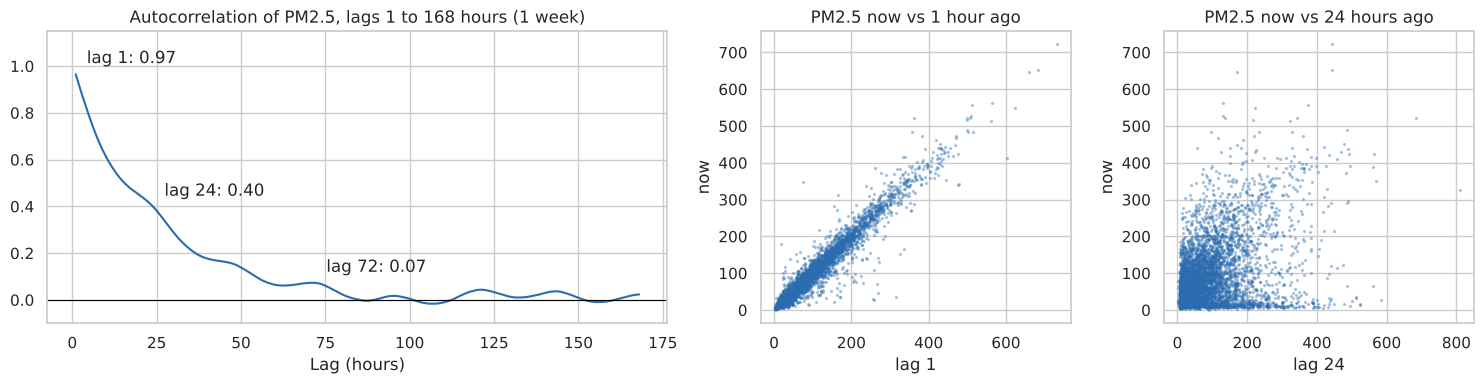

1      0.965
2      0.919
3      0.872
6      0.745
12     0.563
24     0.398
48     0.153
72     0.073
168    0.024
dtype: float64

In [13]:
lags = list(range(1, 169))
acf = pd.Series([df.pm25.autocorr(l) for l in lags], index=lags)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
axes[0].plot(acf.index, acf.values, color="#2b6cb0")
for l in (1, 24, 72):
    axes[0].annotate(f"lag {l}: {acf[l]:.2f}", (l, acf[l]), textcoords="offset points", xytext=(8, 8))
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylim(-0.1, 1.15)
axes[0].set_title("Autocorrelation of PM2.5, lags 1 to 168 hours (1 week)")
axes[0].set_xlabel("Lag (hours)")

sample = df.dropna(subset=["pm25"]).sample(5000, random_state=0)
for ax, l in zip(axes[1:], (1, 24)):
    ax.scatter(df.pm25.shift(l).loc[sample.index], sample.pm25, s=2, alpha=0.3, color="#2b6cb0")
    ax.set_title(f"PM2.5 now vs {l} hour{'s' if l > 1 else ''} ago")
    ax.set_xlabel(f"lag {l}")
    ax.set_ylabel("now")
save("q3_lags")
acf[[1, 2, 3, 6, 12, 24, 48, 72, 168]].round(3)

**Finding:** pollution has a **strong short memory that fades within about 3 days.**

- **One hour ago is almost the same as now** (autocorrelation 0.97). On the scatter plot the points hug the diagonal. That's why "next hour = this hour" is such a hard baseline to beat in modelling.
- **The link weakens steadily:** 0.87 at 3 hours, 0.56 at 12, 0.40 at 24, and close to zero by 72 hours. A smog episode builds and clears over a day or two, then the slate is wiped clean.
- **The 24-hour scatter is much more spread out.** Yesterday at the same time helps a little, but much less than the last few hours.

**For the model:** lags 1, 2 and 3 carry the most information, so we use them. Lag 24 adds the daily cycle. Anything beyond 48 hours adds almost nothing.